# Model and sampling tuning

## Introduction

So I have been working through the book Bayesian Analysis with Python (edition 3), and got stuck on the example from Chapter 3, that deals with analysis of soccer statistics about players ability to score goals

The book's example Notebook is at [https://github.com/aloctavodia/BAP3/blob/main/code_updated/Chp_03.ipynb]

## Difficulties

One difficulty may be that I have chosen to work with the latest Python libraries, and not those that were in play when the book was written.  Given all that, I was able to match the model from the book, and get roughly the same results.  Bayesian analysis with PyMC is a probabilistic adventure, and different runs will give slightly different numbers  (being old school, I found this deeply unsettling, being used to match expected results to many decimal places to be sure I had understood the worked example correctly)

However, the big issue was that the ArViz diagnose() reported all sorts of problems.  With some help from Claude, I was eventually able to resolve most of them.

--------------------
## Implementation

### Imports

In [37]:
import pathlib

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import preliz as pz
import pymc as pm
import xarray as xa

-----------------

### Define helper functions

#### Beta function related

In [38]:
def beta_ab_to_mn(alpha, beta):
    """
    beta_ab_to_mn: converts beta distribution parameters
    """

    nu = alpha + beta
    mu = alpha / nu
    return (mu, nu)


# end beta_ab_to_mn


def beta_mn_to_ab(mu, nu):
    """
    beta_ab_to_mn: converts beta distribution parameters
    """

    alpha = mu * nu
    beta = (1 - mu) * nu
    return (alpha, beta)


# end beta_mn_to_ab(mu, nu)

#### Plotting distributions

In [39]:
def plot_dist(dist, ax):
    """
    plot_dist: plots PyMC known distribution (eg Beta) on Matplotlib axes
    """
    draws = pm.draw(dist, draws=5000, random_seed=42)
    ax.hist(
        draws,
        alpha=0.1,
        density=True,
        bins=100,
        label="PyMC draws",
    )
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.set_title("PyMC Distribution Draw")
    ax.legend()


# end plot_dist

---------------------

## Model building

### Visualize some distributions

These distributions will be used in the model

#### Beta

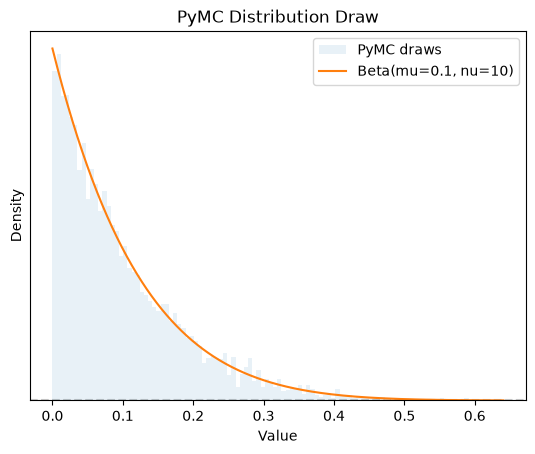

In [40]:
fig, ax = plt.subplots()
mu_pop = 0.1
nu_pop = 10
plot_dist(pm.Beta.dist(mu=mu_pop, nu=nu_pop), ax)
ax = pz.Beta(mu=mu_pop, nu=nu_pop).plot_pdf(ax=ax)
ax.legend()

#### Gamma

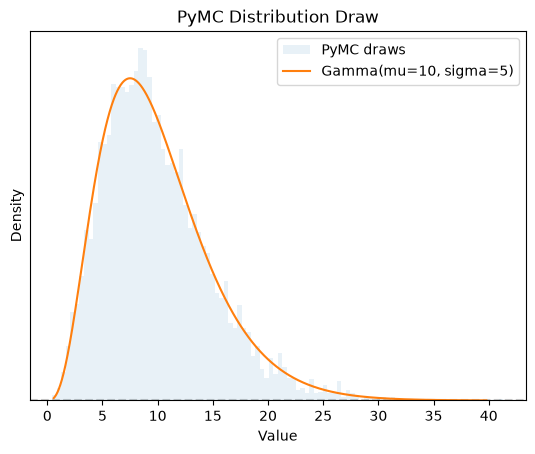

In [41]:
fig, ax = plt.subplots()
mu_pop = 0.1
nu_pop = 10
plot_dist(pm.Gamma.dist(mu=10, sigma=5), ax)
ax = pz.Gamma(mu=10, sigma=5).plot_pdf(ax=ax)
ax.legend()

-----------------

## Dataset load

In [42]:
path = pathlib.Path("data/football_players.csv")
df = pd.read_csv(path)
print(df.head(2))

# change player field position to ctegorical
df["position"] = df["position"].astype("category")

# get the index of the position for every player
position_index = df.position.cat.codes.values

# get the field position code for each position category
position_codes = df["position"].cat.categories

              name position  goals  shots
0   Aaron Connolly       FW      5     59
1  Aaron Cresswell       DF      4     69


-------------------

## Define model

Just run initially with default sampling behavior


In [43]:
# set up a dimension "pos" relating to field positions
coords = {
    "pos": position_codes,
}

#  create model
with pm.Model(coords=coords) as model_1:

    alpha = 1.7
    beta = 5.8

    mu = pm.Beta(
        "mu",
        alpha,
        beta,
    )
    nu = pm.Gamma("nu", mu=125, sigma=50)

    mu_pos = pm.Beta("mu_pos", mu=mu, nu=nu, dims="pos")
    nu_pos = pm.Gamma("nu_pos", mu=125, sigma=50, dims="pos")

    theta = pm.Beta(
        "theta",
        mu=mu_pos[position_index],
        nu=nu_pos[position_index],
    )

    _ = pm.Binomial("y", n=df["shots"].values, p=theta, observed=df["goals"].values)

    idata_1 = pm.sample()

# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [mu, nu, mu_pos, nu_pos, theta]


Output()

#### Graph model 
It matches the book

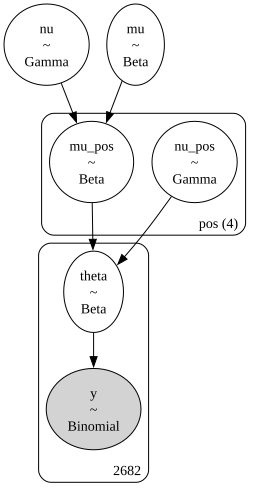

In [44]:
pm.model_to_graphviz(model_1)

####
 Automatically review model sampling run for problems - the moment of truth!

In [45]:
problems = az.diagnose(idata_1)

Divergences
No divergent transitions found.

E-BFMI
Chain 0: E-BFMI = 0.189
Chain 1: E-BFMI = 0.210
Chain 2: E-BFMI = 0.218
Chain 3: E-BFMI = 0.212
E-BFMI values are below the threshold 0.30 which suggests that HMC may have trouble exploring the target distribution.
If possible, try to reparameterize the model.

ESS
The following parameters have fewer than 400 effective samples:
  mu, mu_pos, nu_pos, theta
This suggests that the sampler may not have fully explored the posterior distribution for this parameter.
Consider reparameterizing the model or increasing the number of samples.

R-hat
The following parameters have R-hat values greater than 1.01:
  mu, mu_pos, nu_pos, theta
Such high values indicate incomplete mixing and biased estimation.
You should consider regularizing your model with additional prior information or a more effective parameterization.


### Summary

We have at least three problems reported above

#### E-BFMI
to quote 

    
    Energy Bayesian Fraction of Missing Information (E-BFMI) is a critical diagnostic for Hamiltonian Monte Carlo (HMC) and the No-U-Turn Sampler (NUTS). It measures how efficiently a chain explores the energy levels of the posterior distribution

and 


    0.2 to 0.3	Borderline. ArviZ's az.diagnose() won't always trigger a strict warning at 0.2, but Stan/PyMC backends flag items under 0.3 as a safety margin

#### ESS

to quote

    Total ESS < 400 (or < 100 per chain): Modern convergence standards (such as Vehtari et al., 2021) mandate an absolute minimum of 100 effective samples per chain. If you run the PyMC default of 4 chains, any parameter with a total ess under 400 is a failure.

#### R-hat

To quote

    The rank normalized R-hat diagnostic tests for lack of convergence by comparing the variance between multiple chains to the variance within each chain. If convergence has been achieved, the between-chain and within-chain variances should be identical.
    
    In PyMC, the standard quantitative threshold for model acceptance based on the R̂ (R-hat) diagnostic is R̂ < 1.01 for all parameters.


### Explore ESS first

We look at summaries of the statistics of our model sampling run, and note that ESS values associated with the Goalkeeper field position are low.

to quote  

    ess_bulk: Optimised to check if your parameter's central tendency has stabilised. If this number is low, your point estimates (like the mean) are noisy.
    ess_tail: Optimised to ensure you have enough representation in the outer bounds. If this number is low, your confidence intervals (e.g., hdi_3% or hdi_97%) are unreliable.

In [48]:
az.summary(
    idata_1,
    kind="all",
    var_names=[
        "mu",
        "nu",
        "mu_pos",
        "nu_pos",
    ],
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu,0.095,0.0148,0.072,0.12,324,1011,1.01,0.00083,0.00027
nu,124,46,60,200,1830,2104,1.00,1,0.86
mu_pos[DF],0.0803,0.00198,0.077,0.083,1173,1624,1.00,5.8e-05,3.4e-05
mu_pos[FW],0.13026,0.00223,0.13,0.13,2227,2703,1.00,4.7e-05,3.4e-05
mu_pos[GK],0.075,0.021,0.048,0.12,22,56,1.13,0.0043,0.0022
mu_pos[MF],0.08332,0.00166,0.081,0.086,1789,2247,1.00,3.9e-05,2.7e-05
nu_pos[DF],109,23,80,150,131,171,1.02,2,1.4
nu_pos[FW],71.1,7.8,59,84,862,1326,1.00,0.27,0.16
nu_pos[GK],122,50,55,210,125,160,1.02,4.2,1.6
nu_pos[MF],90,11.8,72,110,376,527,1.00,0.61,0.35


Looking at the first 11 players, we see that Player 6 (Aaron Ramsdale) has a low ESS score, and is a __goalkeeper__!

In [49]:
az.summary(
    idata_1,
    kind="all",
    var_names=[
        "theta",
    ],
    coords={"theta_dim_0": slice(0, 10)},
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
theta[0],0.1091,0.0268,0.07,0.15,5130,2491,1.00,0.00037,0.00046
theta[1],0.0715,0.019,0.044,0.1,5598,2881,1.00,0.00025,0.00032
theta[2],0.0877,0.0261,0.049,0.13,5295,2593,1.00,0.00035,0.00047
theta[3],0.0899,0.03,0.047,0.14,5104,2734,1.00,0.00042,0.00059
theta[4],0.1308,0.0277,0.089,0.18,5899,2971,1.00,0.00036,0.00049
theta[5],0.0895,0.0227,0.056,0.13,6248,2523,1.00,0.00028,0.00043
theta[6],0.076,0.033,0.031,0.13,52,205,1.06,0.0043,0.0015
theta[7],0.1019,0.0205,0.072,0.14,4935,2751,1.00,0.00029,0.00035
theta[8],0.0817,0.0247,0.045,0.12,5310,2077,1.00,0.00031,0.00045
theta[9],0.0592,0.0194,0.03,0.092,2803,2256,1.00,0.00033,0.00035


In [50]:
df.iloc[6, :]

name        Aaron Ramsdale
position                GK
goals                    0
shots                    0
Name: 6, dtype: object

-----------------------

## Explore data harder

Looking a little harder we see that goalkeepers have very low or zero shots at goal, and very few goals from those shots.

This suggests that we don't have enough data to properly model goalkeepers in our goal-scoring analysis.  So, our next model will remove goalkeepers from our dataset!

In [15]:
df[df["shots"] == 0].head()

,name,position,goals,shots
6,Aaron Ramsdale,GK,0,0
59,Aitor Fernández,GK,0,0
63,Albano Bizzarri,GK,0,0
66,Alberto García,GK,0,0
93,Alessio Cragno,GK,0,0


In [14]:
df[df["position"] == "GK"].head()

,name,position,goals,shots
6,Aaron Ramsdale,GK,0,0
59,Aitor Fernández,GK,0,0
62,Alban Lafont,GK,0,1
63,Albano Bizzarri,GK,0,0
66,Alberto García,GK,0,0


We have 165 goalkeepers, and 147 players who never attempted a shot at goal.

In [51]:
len(df[df["shots"] == 0]), len(df[df["position"] == "GK"])

(147, 165)

-------------------

## Prune dataset: remove goalkeepers

We strip goalkeepers from our dataset

In [52]:
path = pathlib.Path("data/football_players.csv")
df = pd.read_csv(path)
df = df[df["position"] != "GK"].copy()

df["position"] = df["position"].astype("category")

position_index = df.position.cat.codes.values


position_codes = df["position"].cat.categories

Run the same model (this time we have only three field positions)

In [53]:
coords = {
    "pos": position_codes,
}


with pm.Model(coords=coords) as model_1:

    alpha = 1.7
    beta = 5.8

    mu = pm.Beta(
        "mu",
        alpha,
        beta,
    )
    nu = pm.Gamma("nu", mu=125, sigma=50)

    mu_pos = pm.Beta("mu_pos", mu=mu, nu=nu, dims="pos")
    nu_pos = pm.Gamma("nu_pos", mu=125, sigma=50, dims="pos")

    theta = pm.Beta(
        "theta",
        mu=mu_pos[position_index],
        nu=nu_pos[position_index],
    )

    _ = pm.Binomial("y", n=df["shots"].values, p=theta, observed=df["goals"].values)

    idata_1 = pm.sample()

# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [mu, nu, mu_pos, nu_pos, theta]


Output()

Look for problem again:

In [54]:
problems = az.diagnose(idata_1)

Divergences
No divergent transitions found.

E-BFMI
Chain 0: E-BFMI = 0.166
Chain 1: E-BFMI = 0.202
Chain 2: E-BFMI = 0.282
Chain 3: E-BFMI = 0.277
E-BFMI values are below the threshold 0.30 which suggests that HMC may have trouble exploring the target distribution.
If possible, try to reparameterize the model.

ESS
The following parameters have fewer than 400 effective samples:
  nu_pos
This suggests that the sampler may not have fully explored the posterior distribution for this parameter.
Consider reparameterizing the model or increasing the number of samples.

R-hat
The following parameters have R-hat values greater than 1.01:
  nu_pos
Such high values indicate incomplete mixing and biased estimation.
You should consider regularizing your model with additional prior information or a more effective parameterization.


-----
#### Deep dive into summary()

It looks like model elements associated with estimating the standard deviation of goal scoring ability for individual positions have low _ESS_ values.

As well, the _R-hat_ values all look good excepting that associated with the standard deviation of Defender goal scoring ability.  The individual player parameters look OK

In [55]:
az.summary(
    idata_1,
    kind="all",
    var_names=[
        "mu",
        "nu",
        "mu_pos",
        "nu_pos",
    ],
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu,0.1014,0.0164,0.076,0.13,3434,2218,1.00,0.00028,0.00031
nu,125,46,60,210,3709,2366,1.00,0.74,0.79
mu_pos[DF],0.0804,0.00192,0.077,0.083,901,1367,1.00,6.4e-05,3.6e-05
mu_pos[FW],0.1304,0.00227,0.13,0.13,1913,2140,1.00,5.2e-05,3.8e-05
mu_pos[MF],0.08338,0.0017,0.081,0.086,1275,1702,1.00,4.8e-05,2.8e-05
nu_pos[DF],108,22,79,150,140,101,1.03,2,1.7
nu_pos[FW],71.1,7.5,60,84,862,1357,1.00,0.25,0.13
nu_pos[MF],89,11.8,72,110,376,454,1.01,0.62,0.37


Show summary for the first 11 players looks good

In [56]:
az.summary(
    idata_1,
    kind="all",
    var_names=[
        "theta",
    ],
    coords={"theta_dim_0": slice(0, 10)},
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
theta[0],0.1097,0.0272,0.069,0.16,4585,2450,1.00,0.0004,0.00049
theta[1],0.0717,0.0192,0.044,0.1,4497,2639,1.00,0.00028,0.00032
theta[2],0.0874,0.0255,0.05,0.13,4518,2792,1.00,0.00037,0.00042
theta[3],0.09,0.03,0.047,0.14,4308,2755,1.00,0.00044,0.00053
theta[4],0.1305,0.0275,0.088,0.18,4431,2592,1.00,0.00041,0.00046
theta[5],0.0901,0.0222,0.058,0.13,5122,2894,1.00,0.00031,0.00039
theta[6],0.1017,0.0201,0.072,0.14,3911,2683,1.00,0.00032,0.00034
theta[7],0.082,0.0243,0.048,0.12,4370,2650,1.00,0.00037,0.00048
theta[8],0.0595,0.0201,0.031,0.094,2646,1996,1.00,0.00038,0.00034
theta[9],0.0862,0.0248,0.05,0.13,4734,2884,1.00,0.00036,0.00046


--------------------------


### Improve pm.sample() call (same prior model)

We might be able to address remaining issues by work harder for longer

    target_accept is a tuning parameter passed to the NUTS (No-U-Turn Sampler) via pm.sample() to adjust the step size during the adaptation phase. 

We set it to a higher value than the default ```target_accept=0.95```

We also tune for longer, and perform more random sampling integration steps: ```tune=2000, draws=5000,```



#### Run model again

In [20]:
coords = {
    "pos": position_codes,
}


with pm.Model(coords=coords) as model_1:

    alpha = 1.7
    beta = 5.8

    mu = pm.Beta(
        "mu",
        alpha,
        beta,
    )
    nu = pm.Gamma("nu", mu=125, sigma=50)

    mu_pos = pm.Beta("mu_pos", mu=mu, nu=nu, dims="pos")
    nu_pos = pm.Gamma("nu_pos", mu=125, sigma=50, dims="pos")

    theta = pm.Beta(
        "theta",
        mu=mu_pos[position_index],
        nu=nu_pos[position_index],
    )

    _ = pm.Binomial("y", n=df["shots"].values, p=theta, observed=df["goals"].values)

    idata_1 = pm.sample(tune=2000, draws=5000, target_accept=0.95)

# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [mu, nu, mu_pos, nu_pos, theta]


Output()

### Run the diagnostic report

In [21]:
problems = az.diagnose(idata_1)

Divergences
No divergent transitions found.

E-BFMI
Chain 0: E-BFMI = 0.227
Chain 1: E-BFMI = 0.233
Chain 2: E-BFMI = 0.267
Chain 3: E-BFMI = 0.267
E-BFMI values are below the threshold 0.30 which suggests that HMC may have trouble exploring the target distribution.
If possible, try to reparameterize the model.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.


#### Success!  

Sort of: we still need to address our low E-BFMI scores.

to quote AI:

    If your other diagnostics—like R̂ and Effective Sample Size (ESS)—look great, a slightly low E-BFMI can sometimes be safely ignored. However, if it drops significantly below 0.20, you should resolve it

For the moment, I am going to go back to the original dataset (with goalkeepers included), and try working harder for longer

-------------------------

## Try harder with full model

Re-create original dataset

In [58]:
path = pathlib.Path("data/football_players.csv")
df = pd.read_csv(path)
df.head(2)

df["position"] = df["position"].astype("category")

position_index = df.position.cat.codes.values


position_codes = df["position"].cat.categories

#### Run same model, with more sampling

In [59]:
coords = {
    "pos": position_codes,
}


with pm.Model(coords=coords) as model_1:

    alpha = 1.7
    beta = 5.8

    mu = pm.Beta(
        "mu",
        alpha,
        beta,
    )
    nu = pm.Gamma("nu", mu=125, sigma=50)

    mu_pos = pm.Beta("mu_pos", mu=mu, nu=nu, dims="pos")
    nu_pos = pm.Gamma("nu_pos", mu=125, sigma=50, dims="pos")

    theta = pm.Beta(
        "theta",
        mu=mu_pos[position_index],
        nu=nu_pos[position_index],
    )

    _ = pm.Binomial("y", n=df["shots"].values, p=theta, observed=df["goals"].values)

    idata_1 = pm.sample(
        tune=3000,
        draws=20000,
        target_accept=0.95,
    )

# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [mu, nu, mu_pos, nu_pos, theta]


Output()

#### Get diagnostics

In [60]:
problems = az.diagnose(idata_1)

Divergences
No divergent transitions found.

E-BFMI
Chain 0: E-BFMI = 0.216
Chain 1: E-BFMI = 0.211
Chain 2: E-BFMI = 0.207
Chain 3: E-BFMI = 0.202
E-BFMI values are below the threshold 0.30 which suggests that HMC may have trouble exploring the target distribution.
If possible, try to reparameterize the model.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.


## Success

Running the model again, but working harder for longer, seems to do the trick.

In the plot below, we peer into the innards of the random sampling machine.  I think we are stuck (just like the sampler) because we have a highly funnel-ized model. Thousands of individual goals per shot prior updates have to funnel back into four field positions means and standard deviations, and then back into the top level distribution in the model, updating the mean and standard deviation. Anyhow, that is how I am understanding the diagnostics

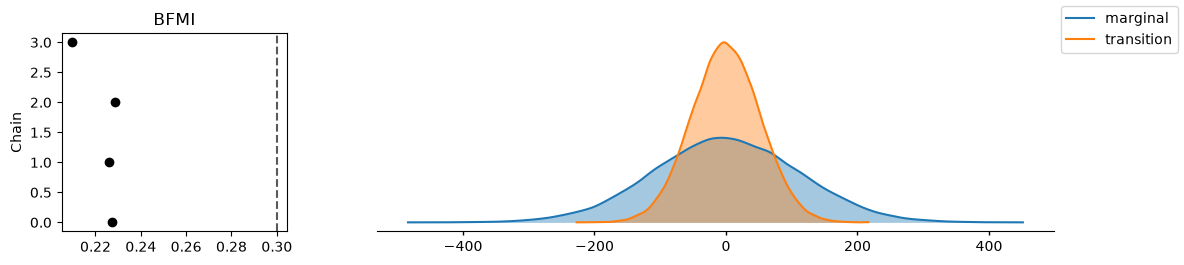

In [31]:
az.plot_energy(idata_1)

To quote

    Narrow Transition Curve (clumped in the middle of a wide Marginal curve). The sampler is stuck. It wants to explore wider energy states (marginal) but its actual jumps (transition) are highly restricted.


#### Summary review

All looks OK, except that the variance of the Goalkeeper goals per shot has a lower value of ESS than any other parameter

In [61]:
az.summary(
    idata_1,
    kind="all",
    var_names=[
        "mu",
        "nu",
        "mu_pos",
        "nu_pos",
    ],
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu,0.0948,0.0151,0.071,0.12,3598,6281,1.00,0.00025,7.9e-05
nu,123.2,45.9,60,200,9196,15007,1.00,0.44,0.18
mu_pos[DF],0.08025,0.00197,0.077,0.083,14840,22864,1.00,1.6e-05,8.8e-06
mu_pos[FW],0.13029,0.00222,0.13,0.13,40978,47932,1.00,1.1e-05,7.4e-06
mu_pos[GK],0.075,0.022,0.042,0.11,635,915,1.01,0.00086,0.00041
mu_pos[MF],0.08332,0.00169,0.081,0.086,26842,39023,1.00,1e-05,6.1e-06
nu_pos[DF],107.3,20,80,140,3015,4862,1.00,0.37,0.25
nu_pos[FW],70.9,7.48,60,84,17072,26461,1.00,0.057,0.032
nu_pos[GK],122,49.8,54,210,2963,3998,1.00,0.86,0.4
nu_pos[MF],89.2,11.5,72,110,7283,11733,1.00,0.14,0.082


----------------

## Conclusions

I understand the source book not wanting to get deep into the details of driving PyMC, but one of the themes of the book is the value of nested hierarchical multi-level models.  Later in the book they do address how to assess the PyMC performance when using nested hierarchical multi-level models.  The usual Internet advice is re-parameterize your model, or de-centre your model.

I strongly recommend always checking __diagnose()__

Call me old fashioned, but I am nostalgic for good old Linear Algebra - at least I could better understand its failure modes!


----------------------------

## Reproducability



In [32]:
%load_ext watermark

In [33]:
%watermark

Last updated: 2026-10-22T17:48:23.608251+10:00

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

Compiler    : MSC v.1944 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 170 Stepping 4, GenuineIntel
CPU cores   : 22
Architecture: 64bit



In [34]:
%watermark -h -iv -co

conda environment: bayes_env

Hostname: INSPIRON16

arviz     : 1.3.0
matplotlib: 3.11.1
numpy     : 2.4.6
pandas    : 3.0.5
preliz    : 0.28.0
pymc      : 6.3.1
xarray    : 2026.7.0

